In [74]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier

from sklearn.datasets import fetch_covtype

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully")

Libraries imported successfully


## Load the Dataset

In [75]:
df = fetch_covtype(as_frame=True, random_state=42)
df = df["frame"]

print("Full dataset shape:", df.shape)
display(df.head())

Full dataset shape: (581012, 55)


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,Wilderness_Area_0,Wilderness_Area_1,Wilderness_Area_2,Wilderness_Area_3,Soil_Type_0,Soil_Type_1,Soil_Type_2,Soil_Type_3,Soil_Type_4,Soil_Type_5,Soil_Type_6,Soil_Type_7,Soil_Type_8,Soil_Type_9,Soil_Type_10,Soil_Type_11,Soil_Type_12,Soil_Type_13,Soil_Type_14,Soil_Type_15,Soil_Type_16,Soil_Type_17,Soil_Type_18,Soil_Type_19,Soil_Type_20,Soil_Type_21,Soil_Type_22,Soil_Type_23,Soil_Type_24,Soil_Type_25,Soil_Type_26,Soil_Type_27,Soil_Type_28,Soil_Type_29,Soil_Type_30,Soil_Type_31,Soil_Type_32,Soil_Type_33,Soil_Type_34,Soil_Type_35,Soil_Type_36,Soil_Type_37,Soil_Type_38,Soil_Type_39,Cover_Type
0,2596.0,51.0,3.0,258.0,0.0,510.0,221.0,232.0,148.0,6279.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5
1,2590.0,56.0,2.0,212.0,-6.0,390.0,220.0,235.0,151.0,6225.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5
2,2804.0,139.0,9.0,268.0,65.0,3180.0,234.0,238.0,135.0,6121.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
3,2785.0,155.0,18.0,242.0,118.0,3090.0,238.0,238.0,122.0,6211.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
4,2595.0,45.0,2.0,153.0,-1.0,391.0,220.0,234.0,150.0,6172.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5


## Dataset Analysis

In [76]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 581012 entries, 0 to 581011
Data columns (total 55 columns):
 #   Column                              Non-Null Count   Dtype  
---  ------                              --------------   -----  
 0   Elevation                           581012 non-null  float64
 1   Aspect                              581012 non-null  float64
 2   Slope                               581012 non-null  float64
 3   Horizontal_Distance_To_Hydrology    581012 non-null  float64
 4   Vertical_Distance_To_Hydrology      581012 non-null  float64
 5   Horizontal_Distance_To_Roadways     581012 non-null  float64
 6   Hillshade_9am                       581012 non-null  float64
 7   Hillshade_Noon                      581012 non-null  float64
 8   Hillshade_3pm                       581012 non-null  float64
 9   Horizontal_Distance_To_Fire_Points  581012 non-null  float64
 10  Wilderness_Area_0                   581012 non-null  float64
 11  Wilderness_Area_1         

In [77]:
print("Missing values:", df.isnull().sum().sum())#gives sum of all columns
print("Missing values column:", df.isnull().sum())#gives sum for each column
print("Duplicate rows:", df.duplicated().sum())


Missing values: 0
Missing values column: Elevation                             0
Aspect                                0
Slope                                 0
Horizontal_Distance_To_Hydrology      0
Vertical_Distance_To_Hydrology        0
Horizontal_Distance_To_Roadways       0
Hillshade_9am                         0
Hillshade_Noon                        0
Hillshade_3pm                         0
Horizontal_Distance_To_Fire_Points    0
Wilderness_Area_0                     0
Wilderness_Area_1                     0
Wilderness_Area_2                     0
Wilderness_Area_3                     0
Soil_Type_0                           0
Soil_Type_1                           0
Soil_Type_2                           0
Soil_Type_3                           0
Soil_Type_4                           0
Soil_Type_5                           0
Soil_Type_6                           0
Soil_Type_7                           0
Soil_Type_8                           0
Soil_Type_9                           0

In [78]:
display(df.describe().T)#.t is for transpose

,count,mean,std,min,25%,50%,75%,max
Elevation,581012.0,2959.365301,279.984734,1859.0,2809.0,2996.0,3163.0,3858.0
Aspect,581012.0,155.656807,111.913721,0.0,58.0,127.0,260.0,360.0
Slope,581012.0,14.103704,7.488242,0.0,9.0,13.0,18.0,66.0
Horizontal_Distance_To_Hydrology,581012.0,269.428217,212.549356,0.0,108.0,218.0,384.0,1397.0
Vertical_Distance_To_Hydrology,581012.0,46.418855,58.295232,-173.0,7.0,30.0,69.0,601.0
Horizontal_Distance_To_Roadways,581012.0,2350.146611,1559.254870,0.0,1106.0,1997.0,3328.0,7117.0
Hillshade_9am,581012.0,212.146049,26.769889,0.0,198.0,218.0,231.0,254.0
Hillshade_Noon,581012.0,223.318716,19.768697,0.0,213.0,226.0,237.0,254.0
Hillshade_3pm,581012.0,142.528263,38.274529,0.0,119.0,143.0,168.0,254.0
Horizontal_Distance_To_Fire_Points,581012.0,1980.291226,1324.195210,0.0,1024.0,1710.0,2550.0,7173.0


## Target Distribution

Class Counts: Cover_Type
2    283301
1    211840
3     35754
7     20510
6     17367
5      9493
4      2747
Name: count, dtype: int64


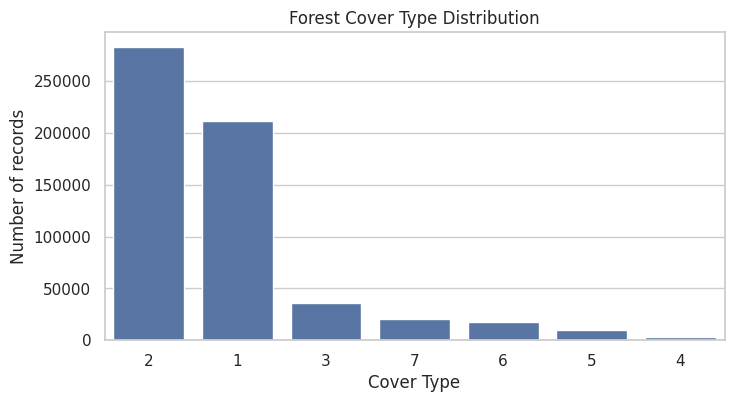

In [79]:
class_counts = df["Cover_Type"].value_counts()
print("Class Counts:",class_counts)

plt.figure(figsize=(8, 4))
sns.barplot(x=class_counts.index.astype(str), y=class_counts.values)
plt.title("Forest Cover Type Distribution")
plt.xlabel("Cover Type")
plt.ylabel("Number of records")
plt.show()

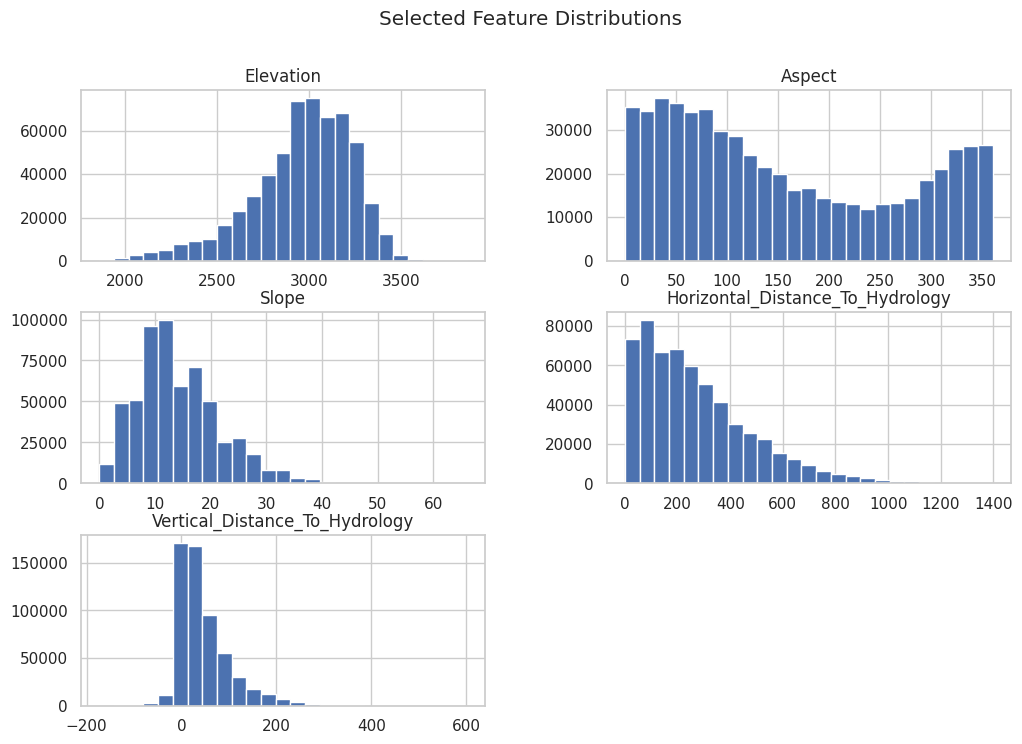

In [80]:
numeric_columns = [
    "Elevation", "Aspect", "Slope",
    "Horizontal_Distance_To_Hydrology",
    "Vertical_Distance_To_Hydrology"
]

df[numeric_columns].hist(figsize=(12, 8), bins=25)
plt.suptitle("Selected Feature Distributions")
plt.show()

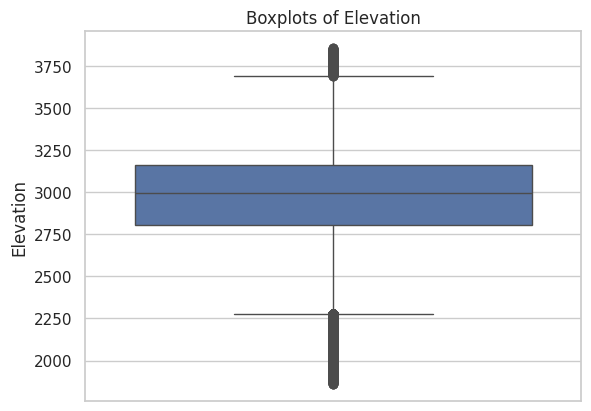

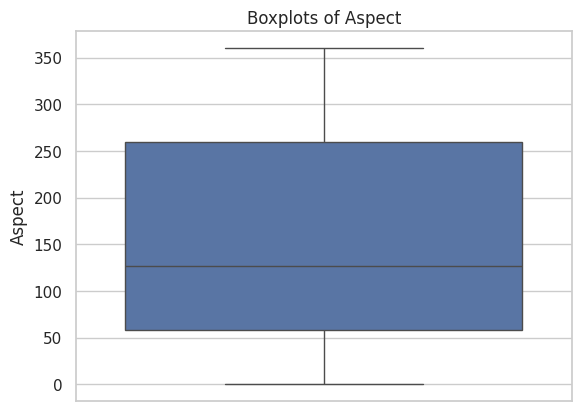

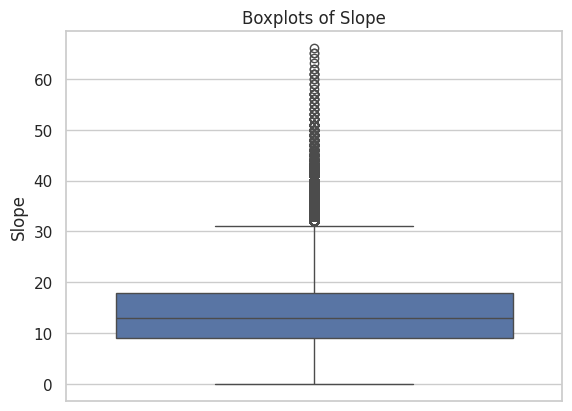

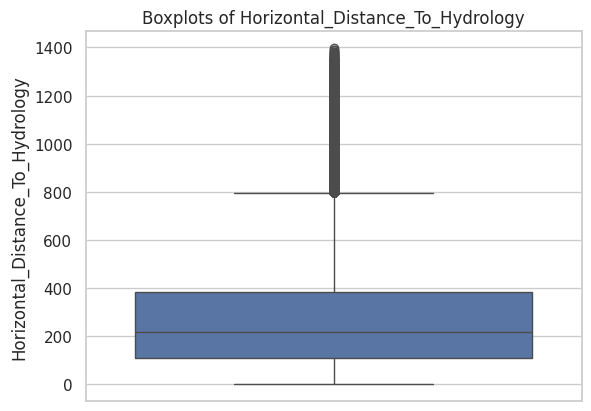

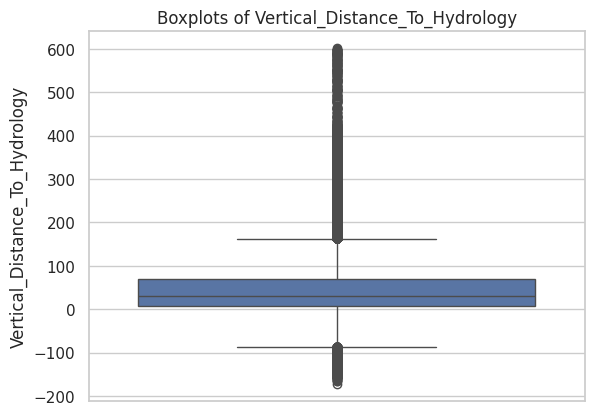

In [81]:
for col in numeric_columns:


  sns.boxplot(df[col])
  plt.title("Boxplots of "+ col )
  plt.xticks(rotation=25)
  plt.show()

## Corelation between selected features

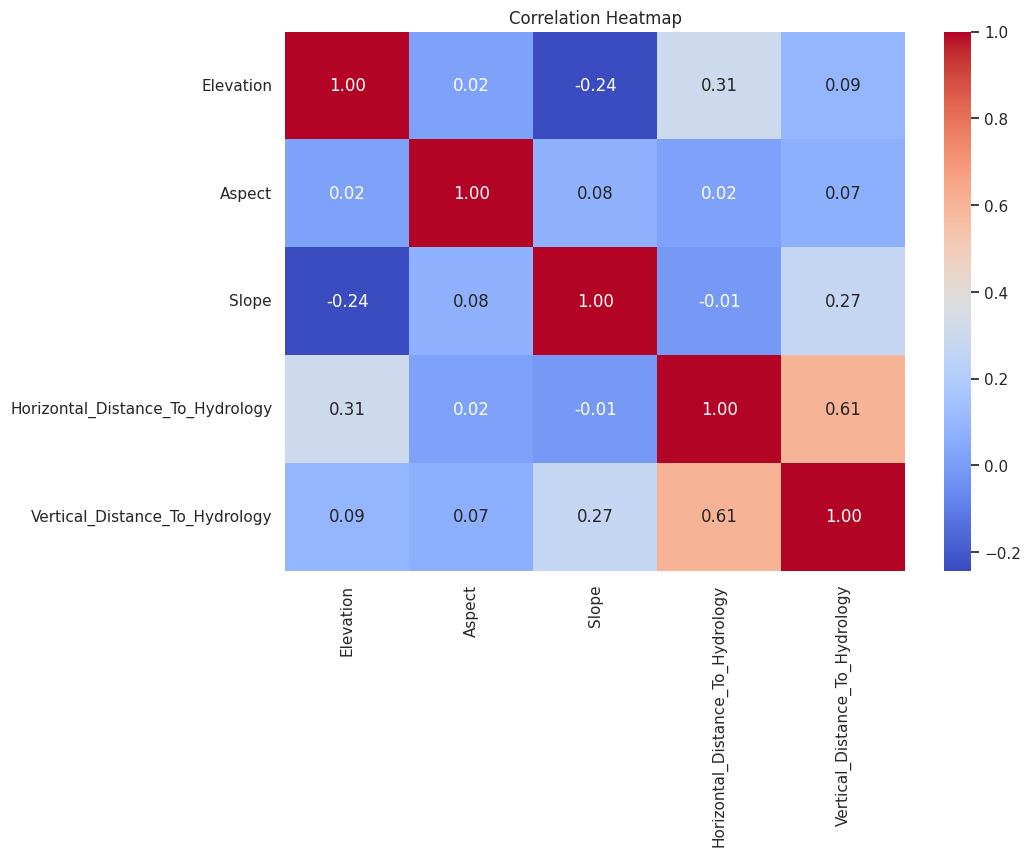

In [82]:
plt.figure(figsize=(10, 7))
sns.heatmap(df[numeric_columns].corr(), annot=True, cmap="coolwarm", fmt=".2f")#.2f round's it off to 2 decimal point
plt.title("Correlation Heatmap")
plt.show()

## Splitting and Preprocessing

In [83]:
# Separate input features and target.
X = df.drop("Cover_Type", axis=1)
y = df["Cover_Type"]

# All input columns in Forest CoverType are numerical.
numeric_columns = X.select_dtypes(include=["number"]).columns.tolist()

print("Features:", X.shape)
print("Target:", y.shape)
print("Number of numerical features:", len(numeric_columns))
print("Missing values in X:", X.isnull().sum().sum())

# Split original, unprocessed features and target first.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Create ColumnTransformer for all numerical input features.
preprocessor = ColumnTransformer(
    transformers=[("scale", StandardScaler(), numeric_columns)],
    remainder="drop"
)

# Fit only on training data, then transform both sets.
X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Training feature columns:", X_train.shape[1])

Features: (581012, 54)
Target: (581012,)
Number of numerical features: 54
Missing values in X: 0
Training rows: 464809
Testing rows: 116203
Training feature columns: 54


In [84]:
display(X.head())

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,Wilderness_Area_0,Wilderness_Area_1,Wilderness_Area_2,Wilderness_Area_3,Soil_Type_0,Soil_Type_1,Soil_Type_2,Soil_Type_3,Soil_Type_4,Soil_Type_5,Soil_Type_6,Soil_Type_7,Soil_Type_8,Soil_Type_9,Soil_Type_10,Soil_Type_11,Soil_Type_12,Soil_Type_13,Soil_Type_14,Soil_Type_15,Soil_Type_16,Soil_Type_17,Soil_Type_18,Soil_Type_19,Soil_Type_20,Soil_Type_21,Soil_Type_22,Soil_Type_23,Soil_Type_24,Soil_Type_25,Soil_Type_26,Soil_Type_27,Soil_Type_28,Soil_Type_29,Soil_Type_30,Soil_Type_31,Soil_Type_32,Soil_Type_33,Soil_Type_34,Soil_Type_35,Soil_Type_36,Soil_Type_37,Soil_Type_38,Soil_Type_39
0,2596.0,51.0,3.0,258.0,0.0,510.0,221.0,232.0,148.0,6279.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2590.0,56.0,2.0,212.0,-6.0,390.0,220.0,235.0,151.0,6225.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2804.0,139.0,9.0,268.0,65.0,3180.0,234.0,238.0,135.0,6121.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2785.0,155.0,18.0,242.0,118.0,3090.0,238.0,238.0,122.0,6211.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2595.0,45.0,2.0,153.0,-1.0,391.0,220.0,234.0,150.0,6172.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [85]:
df.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,Wilderness_Area_0,Wilderness_Area_1,Wilderness_Area_2,Wilderness_Area_3,Soil_Type_0,Soil_Type_1,Soil_Type_2,Soil_Type_3,Soil_Type_4,Soil_Type_5,Soil_Type_6,Soil_Type_7,Soil_Type_8,Soil_Type_9,Soil_Type_10,Soil_Type_11,Soil_Type_12,Soil_Type_13,Soil_Type_14,Soil_Type_15,Soil_Type_16,Soil_Type_17,Soil_Type_18,Soil_Type_19,Soil_Type_20,Soil_Type_21,Soil_Type_22,Soil_Type_23,Soil_Type_24,Soil_Type_25,Soil_Type_26,Soil_Type_27,Soil_Type_28,Soil_Type_29,Soil_Type_30,Soil_Type_31,Soil_Type_32,Soil_Type_33,Soil_Type_34,Soil_Type_35,Soil_Type_36,Soil_Type_37,Soil_Type_38,Soil_Type_39,Cover_Type
0,2596.0,51.0,3.0,258.0,0.0,510.0,221.0,232.0,148.0,6279.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5
1,2590.0,56.0,2.0,212.0,-6.0,390.0,220.0,235.0,151.0,6225.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5
2,2804.0,139.0,9.0,268.0,65.0,3180.0,234.0,238.0,135.0,6121.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
3,2785.0,155.0,18.0,242.0,118.0,3090.0,238.0,238.0,122.0,6211.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
4,2595.0,45.0,2.0,153.0,-1.0,391.0,220.0,234.0,150.0,6172.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5


## Verify Class Proportions are retained

Class Counts: Cover_Type
2    226640
1    169472
3     28603
7     16408
6     13894
5      7594
4      2198
Name: count, dtype: int64


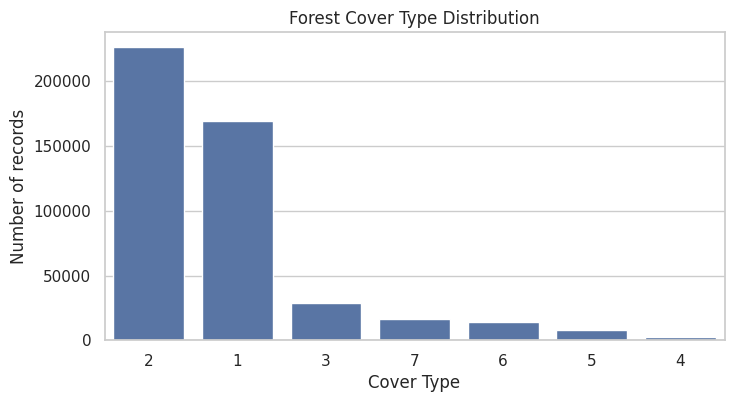

In [86]:
class_counts = y_train.value_counts()
print("Class Counts:",class_counts)

plt.figure(figsize=(8, 4))
sns.barplot(x=class_counts.index.astype(str), y=class_counts.values)
plt.title("Forest Cover Type Distribution")
plt.xlabel("Cover Type")
plt.ylabel("Number of records")
plt.show()

## Baseline Tests

In [73]:
# Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)

# Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# Linear SVM
svm_model = LinearSVC(random_state=42, max_iter=5000)

# Train models on preprocessed training data.
dt_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)
svm_model.fit(X_train, y_train)

# Make predictions on preprocessed test data.
dt_pred = dt_model.predict(X_test)
rf_pred = rf_model.predict(X_test)
svm_pred = svm_model.predict(X_test)

print("Baseline models trained.")

Baseline models trained.


In [87]:
# Majority-class baseline: predicts the most common cover type every time.
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)
dummy_pred = dummy_model.predict(X_test)

baseline_results = pd.DataFrame({
    "Model": ["Majority Class Baseline", "Decision Tree", "Random Forest", "SVM"],
    "Accuracy": [
        accuracy_score(y_test, dummy_pred),
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, svm_pred)
    ],
    "Precision_macro": [
        precision_score(y_test, dummy_pred, average="macro", zero_division=0),
        precision_score(y_test, dt_pred, average="macro", zero_division=0),
        precision_score(y_test, rf_pred, average="macro", zero_division=0),
        precision_score(y_test, svm_pred, average="macro", zero_division=0)
    ],
    "Recall_macro": [
        recall_score(y_test, dummy_pred, average="macro", zero_division=0),
        recall_score(y_test, dt_pred, average="macro", zero_division=0),
        recall_score(y_test, rf_pred, average="macro", zero_division=0),
        recall_score(y_test, svm_pred, average="macro", zero_division=0)
    ],
    "F1_macro": [
        f1_score(y_test, dummy_pred, average="macro", zero_division=0),
        f1_score(y_test, dt_pred, average="macro", zero_division=0),
        f1_score(y_test, rf_pred, average="macro", zero_division=0),
        f1_score(y_test, svm_pred, average="macro", zero_division=0)
    ]
})
display(baseline_results.round(4))


,Model,Accuracy,Precision_macro,Recall_macro,F1_macro
0,Majority Class Baseline,0.4876,0.0697,0.1429,0.0937
1,Decision Tree,0.9389,0.9037,0.9045,0.9041
2,Random Forest,0.9533,0.9460,0.9053,0.9240
3,SVM,0.7114,0.6207,0.4467,0.4556


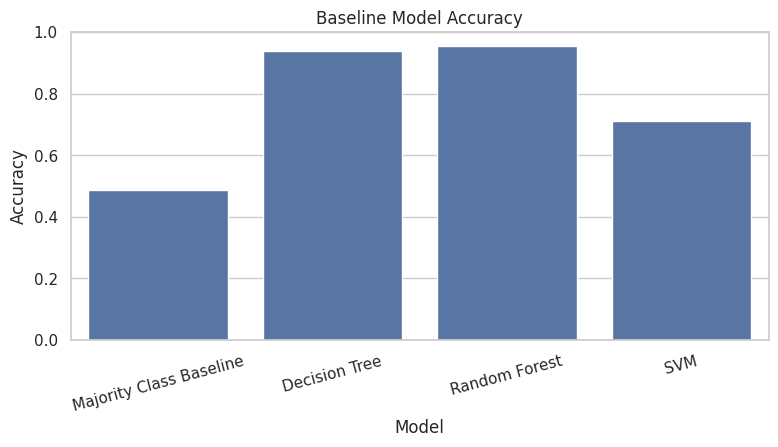

In [88]:
plt.figure(figsize=(9, 4))
sns.barplot(data=baseline_results, x="Model", y="Accuracy")
plt.title("Baseline Model Accuracy")
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.show()


In [89]:
size_rows = []

# Use the same held-out test set for all dataset sizes.
for size in [2000, 5000, 8000]:
    if size == len(X_train_raw):
        X_small = X_train_raw.copy()
        y_small = y_train.copy()
    else:
        X_small, _, y_small, _ = train_test_split(
            X_train_raw, y_train, train_size=size,
            random_state=42, stratify=y_train
        )

    # Fit preprocessing only on this training subset.
    size_preprocessor = ColumnTransformer(
        transformers=[("scale", StandardScaler(), numeric_columns)],
        remainder="drop"
    )
    X_small_processed = size_preprocessor.fit_transform(X_small)
    X_test_processed = size_preprocessor.transform(X_test_raw)

    # Decision Tree
    dt_size_model = DecisionTreeClassifier(random_state=42)
    start = time.time()
    dt_size_model.fit(X_small_processed, y_small)
    pred = dt_size_model.predict(X_test_processed)
    elapsed = time.time() - start
    size_rows.append({
        "Training_Size": size, "Model": "Decision Tree",
        "Accuracy": accuracy_score(y_test, pred),
        "F1_macro": f1_score(y_test, pred, average="macro", zero_division=0),
        "Training_and_Prediction_Time_sec": elapsed
    })

    # Random Forest
    rf_size_model = RandomForestClassifier(n_estimators=100, random_state=42)
    start = time.time()
    rf_size_model.fit(X_small_processed, y_small)
    pred = rf_size_model.predict(X_test_processed)
    elapsed = time.time() - start
    size_rows.append({
        "Training_Size": size, "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, pred),
        "F1_macro": f1_score(y_test, pred, average="macro", zero_division=0),
        "Training_and_Prediction_Time_sec": elapsed
    })

size_results = pd.DataFrame(size_rows)
display(size_results.round(4))

,Training_Size,Model,Accuracy,F1_macro,Training_and_Prediction_Time_sec
0,2000,Decision Tree,0.6509,0.4906,0.0703
1,2000,Random Forest,0.7410,0.5323,2.7454
2,5000,Decision Tree,0.6920,0.5427,0.1361
3,5000,Random Forest,0.7824,0.6221,4.1675
4,8000,Decision Tree,0.7126,0.5807,0.1832
5,8000,Random Forest,0.8000,0.6570,6.0173


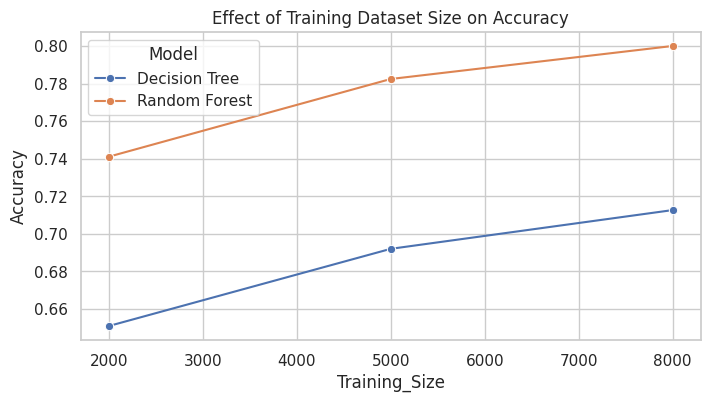

In [90]:
plt.figure(figsize=(8, 4))
sns.lineplot(data=size_results, x="Training_Size", y="Accuracy", hue="Model", marker="o")
plt.title("Effect of Training Dataset Size on Accuracy")
plt.ylabel("Accuracy")
plt.show()

In [ ]:
terrain_features = [
    "Elevation", "Aspect", "Slope",
    "Horizontal_Distance_To_Hydrology",
    "Vertical_Distance_To_Hydrology",
    "Horizontal_Distance_To_Roadways",
    "Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm",
    "Horizontal_Distance_To_Fire_Points"
]
terrain_features = [col for col in terrain_features if col in X.columns]
feature_rows = []

for feature_group, columns in [
    ("Terrain features only", terrain_features),
    ("All features", X.columns.tolist())
]:
    feature_preprocessor = ColumnTransformer(
        transformers=[("scale", StandardScaler(), columns)],
        remainder="drop"
    )
    X_train_features = feature_preprocessor.fit_transform(X_train_raw[columns])
    X_test_features = feature_preprocessor.transform(X_test_raw[columns])

    # Decision Tree
    dt_feature_model = DecisionTreeClassifier(random_state=42)
    dt_feature_model.fit(X_train_features, y_train)
    pred = dt_feature_model.predict(X_test_features)
    feature_rows.append({
        "Feature_Group": feature_group, "Number_of_Features": len(columns),
        "Model": "Decision Tree", "Accuracy": accuracy_score(y_test, pred),
        "F1_macro": f1_score(y_test, pred, average="macro", zero_division=0)
    })

    # Random Forest
    rf_feature_model = RandomForestClassifier(n_estimators=100, random_state=42)
    rf_feature_model.fit(X_train_features, y_train)
    pred = rf_feature_model.predict(X_test_features)
    feature_rows.append({
        "Feature_Group": feature_group, "Number_of_Features": len(columns),
        "Model": "Random Forest", "Accuracy": accuracy_score(y_test, pred),
        "F1_macro": f1_score(y_test, pred, average="macro", zero_division=0)
    })

feature_results = pd.DataFrame(feature_rows)
display(feature_results.round(4))

In [ ]:
plt.figure(figsize=(8, 4))
sns.barplot(data=feature_results, x="Feature_Group", y="Accuracy", hue="Model")
plt.title("Model Performance by Feature Group")
plt.ylim(0, 1)
plt.show()

In [ ]:
parameter_rows = []

# Decision Tree: compare maximum depth.
for depth in [5, 10, None]:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)

    start = time.time()
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    parameter_rows.append({
        "Model": "Decision Tree",
        "Setting": "max_depth=" + str(depth),
        "Accuracy": accuracy_score(y_test, pred),
        "F1_macro": f1_score(y_test, pred, average="macro", zero_division=0),
        "Time_sec": time.time() - start
    })

# Random Forest: compare number of trees.
for trees in [50, 100, 200]:
    model = RandomForestClassifier(n_estimators=trees, random_state=42)

    start = time.time()
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    parameter_rows.append({
        "Model": "Random Forest",
        "Setting": "n_estimators=" + str(trees),
        "Accuracy": accuracy_score(y_test, pred),
        "F1_macro": f1_score(y_test, pred, average="macro", zero_division=0),
        "Time_sec": time.time() - start
    })

parameter_results = pd.DataFrame(parameter_rows)
display(parameter_results.round(4))

In [ ]:
plt.figure(figsize=(10, 4))
sns.barplot(data=parameter_results, x="Setting", y="Accuracy", hue="Model")
plt.title("Effect of Hyperparameter Settings on Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.show()

In [ ]:
split_seeds = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
split_rows = []

for seed in split_seeds:
    X_tr_raw, X_te_raw, y_tr, y_te = train_test_split(
        X, y, test_size=0.20, random_state=seed, stratify=y
    )

    # Fit preprocessing separately for this split, using training rows only.
    seed_preprocessor = ColumnTransformer(
        transformers=[("scale", StandardScaler(), numeric_columns)],
        remainder="drop"
    )
    X_tr = seed_preprocessor.fit_transform(X_tr_raw)
    X_te = seed_preprocessor.transform(X_te_raw)

    # Decision Tree
    dt = DecisionTreeClassifier(random_state=42)
    dt.fit(X_tr, y_tr)
    pred = dt.predict(X_te)
    split_rows.append({
        "Seed": seed, "Model": "Decision Tree",
        "Accuracy": accuracy_score(y_te, pred),
        "F1_macro": f1_score(y_te, pred, average="macro", zero_division=0)
    })

    # Random Forest
    rf = RandomForestClassifier(n_estimators=100, random_state=42)
    rf.fit(X_tr, y_tr)
    pred = rf.predict(X_te)
    split_rows.append({
        "Seed": seed, "Model": "Random Forest",
        "Accuracy": accuracy_score(y_te, pred),
        "F1_macro": f1_score(y_te, pred, average="macro", zero_division=0)
    })

    # Linear SVM
    svm = LinearSVC(random_state=42, max_iter=5000)
    svm.fit(X_tr, y_tr)
    pred = svm.predict(X_te)
    split_rows.append({
        "Seed": seed, "Model": "SVM",
        "Accuracy": accuracy_score(y_te, pred),
        "F1_macro": f1_score(y_te, pred, average="macro", zero_division=0)
    })

split_results = pd.DataFrame(split_rows)
display(split_results)

## 18. Analyze train/test split results

In [ ]:
split_summary = split_results.groupby("Model").agg(
    Mean_Accuracy=("Accuracy", "mean"),
    Std_Accuracy=("Accuracy", "std"),
    Min_Accuracy=("Accuracy", "min"),
    Max_Accuracy=("Accuracy", "max"),
    Mean_F1=("F1_macro", "mean")
).reset_index()

display(split_summary.round(4))

In [ ]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=split_results, x="Model", y="Accuracy")
plt.title("Accuracy Variation Across Split Seeds")
plt.ylim(0, 1)
plt.show()

In [ ]:
plt.figure(figsize=(10, 5))
sns.lineplot(data=split_results, x="Seed", y="Accuracy", hue="Model", marker="o")
plt.title("Accuracy by Train/Test Split Seed")
plt.ylim(0, 1)
plt.show()

In [ ]:
cv_seeds = [11, 22, 33]
cv_rows = []

for seed in cv_seeds:
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

    for fold, (train_index, test_index) in enumerate(cv.split(X, y), start=1):
        X_fold_train_raw = X.iloc[train_index]
        X_fold_test_raw = X.iloc[test_index]
        y_fold_train = y.iloc[train_index]
        y_fold_test = y.iloc[test_index]

        # Fit preprocessing only on this fold's training portion.
        fold_preprocessor = ColumnTransformer(
            transformers=[("scale", StandardScaler(), numeric_columns)],
            remainder="drop"
        )
        X_fold_train = fold_preprocessor.fit_transform(X_fold_train_raw)
        X_fold_test = fold_preprocessor.transform(X_fold_test_raw)

        # Decision Tree
        dt_cv_model = DecisionTreeClassifier(random_state=42)
        dt_cv_model.fit(X_fold_train, y_fold_train)
        pred = dt_cv_model.predict(X_fold_test)
        cv_rows.append({
            "CV_Seed": seed, "Fold": fold, "Model": "Decision Tree",
            "Accuracy": accuracy_score(y_fold_test, pred),
            "F1_macro": f1_score(y_fold_test, pred, average="macro", zero_division=0)
        })

        # Random Forest
        rf_cv_model = RandomForestClassifier(n_estimators=100, random_state=42)
        rf_cv_model.fit(X_fold_train, y_fold_train)
        pred = rf_cv_model.predict(X_fold_test)
        cv_rows.append({
            "CV_Seed": seed, "Fold": fold, "Model": "Random Forest",
            "Accuracy": accuracy_score(y_fold_test, pred),
            "F1_macro": f1_score(y_fold_test, pred, average="macro", zero_division=0)
        })

        # Linear SVM
        svm_cv_model = LinearSVC(random_state=42, max_iter=5000)
        svm_cv_model.fit(X_fold_train, y_fold_train)
        pred = svm_cv_model.predict(X_fold_test)
        cv_rows.append({
            "CV_Seed": seed, "Fold": fold, "Model": "SVM",
            "Accuracy": accuracy_score(y_fold_test, pred),
            "F1_macro": f1_score(y_fold_test, pred, average="macro", zero_division=0)
        })

cv_results = pd.DataFrame(cv_rows)
display(cv_results)

In [ ]:
cv_summary = cv_results.groupby("Model").agg(
    Mean_Accuracy=("Accuracy", "mean"),
    Std_Accuracy=("Accuracy", "std"),
    Mean_F1=("F1_macro", "mean"),
    Std_F1=("F1_macro", "std")
).reset_index()

display(cv_summary.round(4))

In [ ]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=cv_results, x="Model", y="Accuracy")
plt.title("Cross-Validation Accuracy Across Folds and Seeds")
plt.ylim(0, 1)
plt.show()

In [ ]:
plt.figure(figsize=(9, 5))
sns.barplot(data=cv_results, x="Model", y="Accuracy", errorbar="sd")
plt.title("Mean Cross-Validation Accuracy (Error Bars: Standard Deviation)")
plt.ylim(0, 1)
plt.show()

In [ ]:
# Create the same train/test split for both repeated runs.
X_tr_raw, X_te_raw, y_tr, y_te = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# First preprocessing and Random Forest run.
repeat_preprocessor_1 = ColumnTransformer(
    transformers=[("scale", StandardScaler(), numeric_columns)],
    remainder="drop"
)
X_tr_1 = repeat_preprocessor_1.fit_transform(X_tr_raw)
X_te_1 = repeat_preprocessor_1.transform(X_te_raw)

repeat_rf_1 = RandomForestClassifier(n_estimators=100, random_state=42)
repeat_rf_1.fit(X_tr_1, y_tr)
pred_1 = repeat_rf_1.predict(X_te_1)

# Repeat with the same data, preprocessing and model settings.
repeat_preprocessor_2 = ColumnTransformer(
    transformers=[("scale", StandardScaler(), numeric_columns)],
    remainder="drop"
)
X_tr_2 = repeat_preprocessor_2.fit_transform(X_tr_raw)
X_te_2 = repeat_preprocessor_2.transform(X_te_raw)

repeat_rf_2 = RandomForestClassifier(n_estimators=100, random_state=42)
repeat_rf_2.fit(X_tr_2, y_tr)
pred_2 = repeat_rf_2.predict(X_te_2)

print("First accuracy:", accuracy_score(y_te, pred_1))
print("Second accuracy:", accuracy_score(y_te, pred_2))
print("Predictions identical:", np.array_equal(pred_1, pred_2))

In [ ]:
cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.show()

In [ ]:
print(classification_report(y_test, rf_pred, zero_division=0))